# Tierra: primer prototipo de mapas alineados

Preparación para buscar análogos: reunir **seis variables terrestres** y sus coberturas sobre la malla global de **1° (360 × 180)**. Todavía no calcula semejanzas con Marte.

**Kernel:** seleccionar `marte/.venv/bin/python` y ejecutar en orden. Se descargan únicamente cuatro resúmenes pequeños de Hugging Face, por HTTP a memoria, con verificación SHA256. Los mosaicos detallados quedan remotos y no se crea una caché de TIFF.

Un grado terrestre representa unos **111 km en el ecuador**. El ancho este-oeste disminuye con la latitud. Fuente, tratamiento y licencia en [prototipo.md](./docu/prototipo.md).

In [6]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

TIERRA = Path.cwd()
if (TIERRA / "tierra").is_dir():
    TIERRA = TIERRA / "tierra"
if not (TIERRA / "prototipo_analogos.py").exists():
    raise RuntimeError("Ejecuta desde la raíz del repositorio o desde tierra/")
if Path(sys.prefix).resolve() != (TIERRA.parent / "marte" / ".venv").resolve():
    raise RuntimeError("Selecciona el kernel existente marte/.venv/bin/python")
sys.path.insert(0, str(TIERRA))
import prototipo_analogos as proto

SALIDA = proto.SALIDA
print("Python:", sys.executable)
print("Salida temporal:", SALIDA)

Python: /home/renato/Desktop/HSpace/marte/.venv/bin/python
Salida temporal: /tmp/hspace_tierra_productos/prototipo


## 1. Catálogo y fuentes

- Elevación NASADEM: media de píxeles válidos en metros respecto a EGM96; se conserva su cobertura.
- GHI y albedo NASA POWER: climatología anual **2001–2025**, unidades W/m² y adimensional respectivamente, nativos a 1°.
- Ciudades, agua y vegetación: fracciones entre píxeles clasificados de MODIS IGBP 2021, con suplemento de océano Natural Earth solo donde MODIS no clasifica.

El catálogo publicado guarda tamaños y hashes. Se fija un commit para toda esta ejecución; no se cargan los archivos globales de 15 segundos de arco.

In [7]:
catalogo, revision = proto.cargar_catalogo(TIERRA / "catalogo.json")
print("Dataset:", catalogo["dataset"])
print("Revisión fijada:", revision)
for nombre in proto.ARCHIVOS:
    registro = catalogo["productos"][nombre]
    print(f"{nombre}: {registro['bytes']:,} bytes")

Dataset: Renato-R-V/hspace-datasets
Revisión fijada: 1fee6799d0cc59f52434db6cd6054aec30aaca68
NASADEM_tierra_1grado.tif: 70,662 bytes
GHI_tierra.tif: 44,041 bytes
Albedo_tierra.tif: 34,702 bytes
Fracciones_mascaras_tierra_MODIS_2021_1grado.tif: 234,927 bytes


## 2. Cuadrícula y controles

Todos los resúmenes usan **EPSG:4326**, extensión −180°…180° / −90°…90°, origen −180°, +90° y píxeles de 1°. Se comprueban esas propiedades, las unidades, la climatología, los hashes y los rangos físicos.

La radiación conserva su resolución nativa. NASADEM y las clases del suelo ya se agregaron desde las capas detalladas: no se infla la resolución climática a 463 m. Los desconocidos permanecen como `NaN`, y la cobertura se conserva en dos bandas separadas.

In [8]:
datos, coberturas, procedencia = proto.preparar_datos(catalogo, revision)
proto.resumir(datos, coberturas)

Verificado en memoria: NASADEM_tierra_1grado.tif · 70,662 bytes · 2 banda(s)
Verificado en memoria: GHI_tierra.tif · 44,041 bytes · 1 banda(s)
Verificado en memoria: Albedo_tierra.tif · 34,702 bytes · 1 banda(s)
Verificado en memoria: Fracciones_mascaras_tierra_MODIS_2021_1grado.tif · 234,927 bytes · 4 banda(s)
Elevación NASADEM        22.41% con datos | -45.4776 a 5409.14 [m EGM96]
GHI terrestre           100.00% con datos | 55.25 a 307 [W/m²]
Albedo terrestre        100.00% con datos | 0.0200195 a 0.800781 [adimensional]
Fracción ciudades        91.35% con datos | 0 a 0.414201 [fracción clasificada]
Fracción agua            91.35% con datos | 0 a 1 [fracción clasificada]
Fracción vegetación      91.35% con datos | 0 a 1 [fracción clasificada]
Forma del cubo: (6, 180, 360)
Cobertura NASADEM: 14,520 celdas con algún píxel de origen; 0 parcialmente cubiertas
Cobertura clasificada: 59,194 celdas con algún píxel de origen; 971 parcialmente cubiertas


## 3. Cubo y cobertura

`cubo` tiene forma **(6 variables, 180 filas, 360 columnas)**, en orden: elevación, GHI, albedo, ciudades, agua y vegetación. Se guarda además un ráster con cobertura NASADEM y cobertura clasificada.

Las fracciones de ciudades/agua/vegetación están condicionadas a los píxeles conocidos; **cobertura cero es un valor válido**, mientras que la fracción temática correspondiente permanece desconocida. No se exige que todas las variables tengan datos para conservar una celda. No se aplica un umbral arbitrario de exclusión a las celdas de 1°.

Las salidas que incluyen fracciones de la máscara mantienen **CC BY-SA 4.0** y la atribución a OpenGeoHub/MODIS y Natural Earth.

In [9]:
cubo = np.stack(list(datos.values()))
print("Forma del cubo:", cubo.shape)
salidas = proto.guardar(datos, coberturas, procedencia, SALIDA)
salidas

Forma del cubo: (6, 180, 360)
GeoTIFF guardado y verificado: /tmp/hspace_tierra_productos/prototipo/tierra_1grado.tif
GeoTIFF guardado y verificado: /tmp/hspace_tierra_productos/prototipo/coberturas_tierra_1grado.tif
Informe del prototipo: /home/renato/Desktop/HSpace/tierra/auditoria/prototipo.json


{'tierra_1grado.tif': '/tmp/hspace_tierra_productos/prototipo/tierra_1grado.tif',
 'coberturas_tierra_1grado.tif': '/tmp/hspace_tierra_productos/prototipo/coberturas_tierra_1grado.tif'}

## 4. Vista conjunta

Los seis paneles comparten extensión; el gris indica NoData. Las fracciones y el albedo mantienen la escala 0–1. El contraste entre percentiles 2 y 98 de elevación y GHI afecta únicamente a su representación, sin cambiar los valores guardados.

Consultar siempre la cobertura de elevación y clasificación antes de interpretar una celda parcialmente cubierta.

Vista conjunta: /tmp/hspace_tierra_productos/prototipo/tierra_conjunto.png


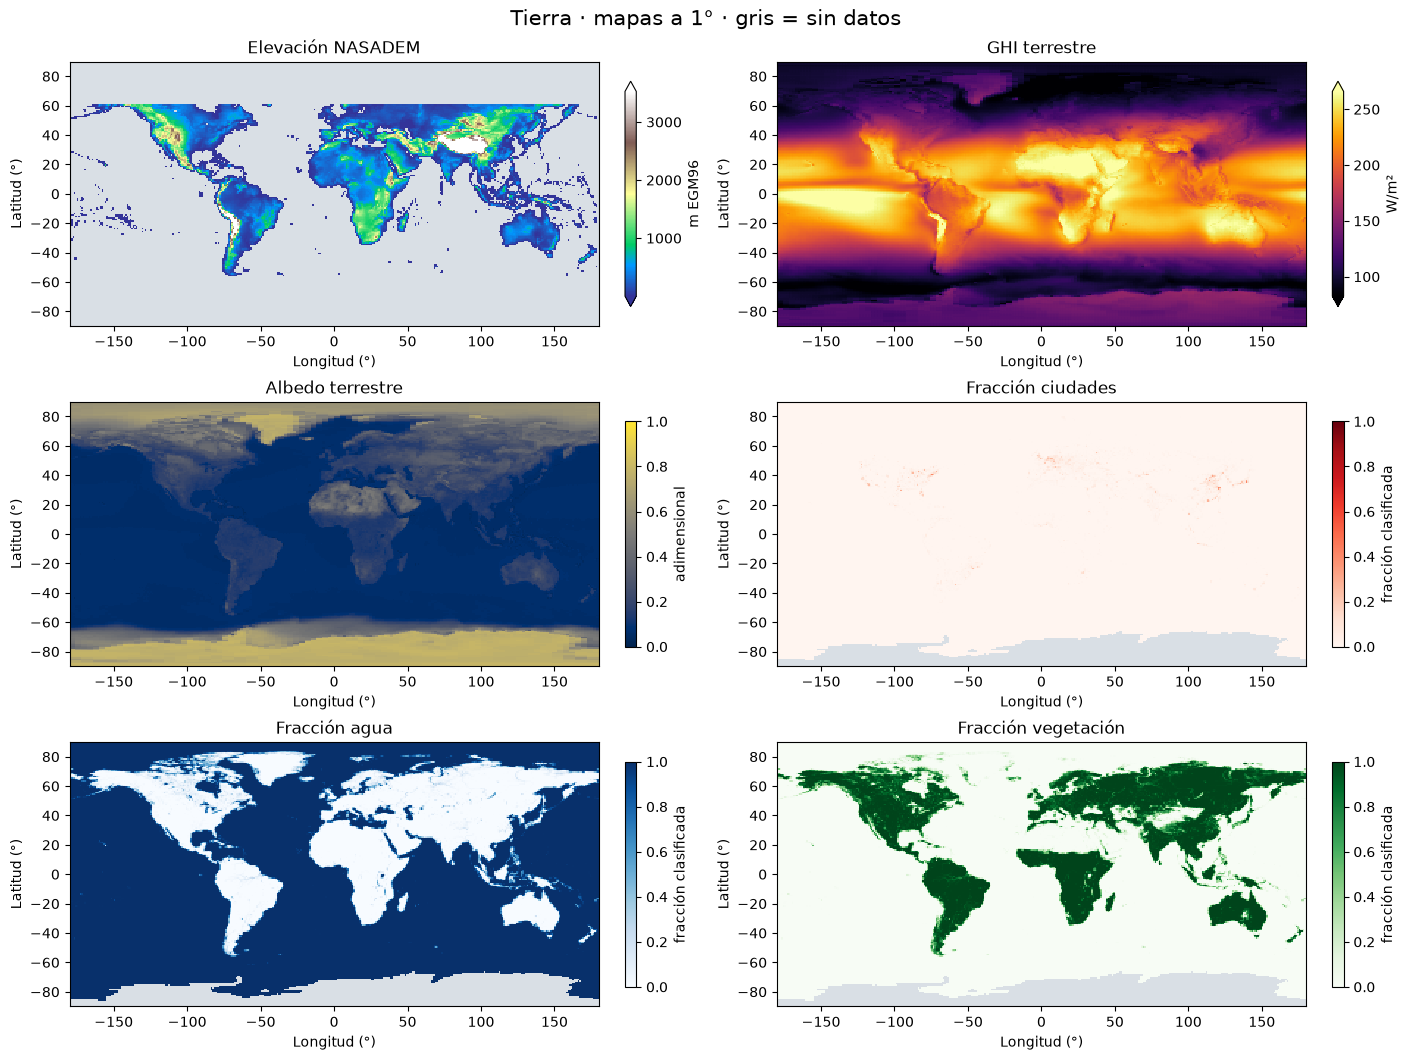

In [10]:
fig = proto.visualizar(datos, SALIDA)
plt.show()

### Próximo paso

La máscara detallada permite excluir ciudades, agua y vegetación mediante sus bits 1, 2 y 4, comprobando antes `valor != 255` para separar desconocidos. El bit 8 identifica el suplemento oceánico Natural Earth; el código 10 sigue siendo agua. La construcción por ventanas y sus límites se explican en [prototipo.md](./docu/prototipo.md).

**Un grado de la Tierra y un grado de Marte no representan la misma distancia.** El GHI marciano es un modelo simplificado a Ls = 18,9°, mientras el terrestre es una climatología anual. El albedo Lambert de Marte y el albedo superficial bajo todo cielo de POWER tienen definiciones diferentes. Deben armonizarse escalas, periodos y variables antes de calcular semejanzas físicas.

Los TIFF preparados permanecen en la carpeta temporal hasta comprobar su publicación en Hugging Face; después pueden eliminarse sin perder las fuentes remotas.